In [17]:
import pandas as pd
import matplotlib.pyplot as plt

In [18]:
neighborhoods = pd.read_csv("Data/Neighborhoods.csv")["hood"].dropna().unique()

# bridges and facilities in each neighborhood
bridges = pd.read_csv("Data/Bridges.csv")["neighborhood"].value_counts()
facilities = pd.read_csv("Data/Facilities.csv")["neighborhood"].value_counts()

# reported crimes in each neighborhood
# (two small name fixes so the crime file matches the neighborhood list)
crime_names = pd.read_csv("Data/Crimes.csv", low_memory=False)["Neighborhood"]
crime_names = crime_names.str.replace("\u2013", "-").replace("Mount Oliver", "Mt. Oliver")
crimes = crime_names.value_counts()

# total weekday bus trips at all the stops in each neighborhood
stops = pd.read_csv("Data/Busses.csv", low_memory=False)
stops = stops[stops["muni"].str.contains("Pittsburgh")]       # city stops only
transit = stops.groupby("hood")["trips_wd"].sum()

# The bus file combines two neighborhoods into one name, so give both the total
both = transit.pop("Arlington-Arlington Heights")
transit["Arlington"] = both
transit["Arlington Heights"] = both

In [19]:
metrics = pd.DataFrame({
    "Bridges": bridges,
    "Transit": transit,
    "Facilities": facilities,
    "Crime": crimes,
})
metrics = metrics.reindex(neighborhoods).fillna(0) # metrics with no data = 0

In [20]:
scores = metrics.rank(pct=True)          # 1.0 = best of all neighborhoods, near 0 = worst
scores["Crime"] = 1 - scores["Crime"]    # flips crime, so less crime is better
scores["Total"] = scores.sum(axis=1)     # add the four scores (max rate of 4)
scores = scores.sort_values("Total", ascending=False)

In [21]:
print(f"Best neighborhood: {scores.index[0]} (total score {scores['Total'].iloc[0]:.2f} out of 4)")

Best neighborhood: Squirrel Hill South (total score 3.01 out of 4)


In [22]:
top5 = scores.head(5).round(2).reset_index()
top5.columns = ["Neighborhood", "Bridges", "Transit", "Facilities", "Low Crime", "Total Score"]
top5.index = range(1, 6)
top5.index.name = "Rank"
top5

,Neighborhood,Bridges,Transit,Facilities,Low Crime,Total Score
Rank,,,,,,
1,Squirrel Hill South,1.00,0.92,0.99,0.10,3.01
2,Squirrel Hill North,0.71,0.98,0.81,0.43,2.93
3,South Side Slopes,0.92,0.80,0.90,0.30,2.92
4,Central Business District,0.99,1.00,0.85,0.00,2.84
5,Shadyside,0.96,0.97,0.87,0.04,2.83


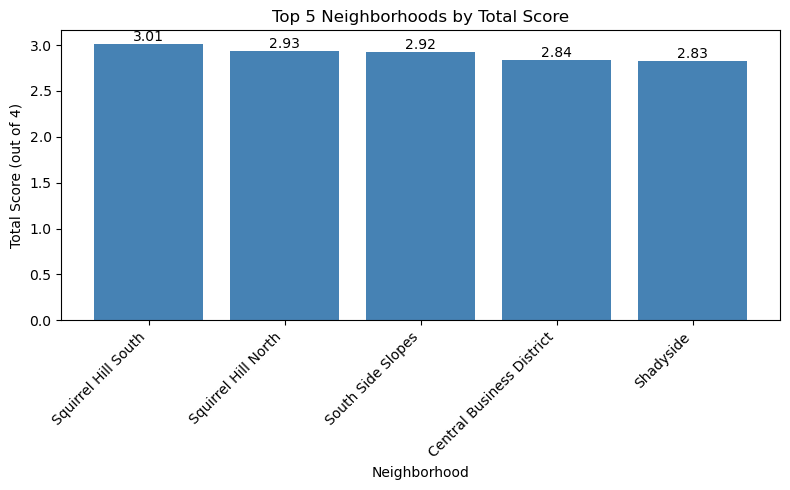

In [23]:
plt.figure(figsize=(8, 5))
plt.bar(top5["Neighborhood"], top5["Total Score"], color="steelblue")
for i, v in enumerate(top5["Total Score"]):
    plt.text(i, v, f"{v:.2f}", ha="center", va="bottom")
plt.title("Top 5 Neighborhoods by Total Score")
plt.xlabel("Neighborhood")
plt.ylabel("Total Score (out of 4)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()